In [1]:

%pip install -q tensorflow matplotlib seaborn scikit-learn pillow requests


Note: you may need to restart the kernel to use updated packages.


In [2]:

import os
import shutil
import random
import requests
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from io import BytesIO

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


In [3]:

DATASET_DIR = "landmark_dataset"
MODEL_PATH = "landmark_detector.keras"

LANDMARKS = [
    "Taj Mahal",
    "Eiffel Tower",
    "Statue of Liberty",
    "Big Ben",
    "Sydney Opera House",
    "Colosseum",
    "Burj Khalifa",
    "Gateway of India"
]

IMAGES_PER_LANDMARK = 50
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 8
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Classes:", LANDMARKS)


Classes: ['Taj Mahal', 'Eiffel Tower', 'Statue of Liberty', 'Big Ben', 'Sydney Opera House', 'Colosseum', 'Burj Khalifa', 'Gateway of India']


In [4]:


def get_commons_images(search_term, limit=100):
    api_url = "https://commons.wikimedia.org/w/api.php"
    params = {
        "action": "query",
        "format": "json",
        "generator": "search",
        "gsrsearch": search_term,
        "gsrnamespace": 6,
        "gsrlimit": min(limit, 100),
        "prop": "imageinfo",
        "iiprop": "url",
        "iiurlwidth": 500
    }
    headers = {"User-Agent": "LandmarkDetectionStudentProject/1.0"}
    r = requests.get(api_url, params=params, headers=headers, timeout=30)
    r.raise_for_status()
    data = r.json()

    urls = []
    for page in data.get("query", {}).get("pages", {}).values():
        info = page.get("imageinfo", [])
        if info:
            url = info[0].get("thumburl") or info[0].get("url")
            if url:
                urls.append(url)
    return urls


def download_landmark_images(landmark, folder, target_count=50):
    os.makedirs(folder, exist_ok=True)

    urls = []
    for query in [
        landmark,
        landmark + " landmark",
        landmark + " architecture"
    ]:
        try:
            urls.extend(get_commons_images(query))
        except Exception as e:
            print("Search error:", query, e)

    urls = list(dict.fromkeys(urls))
    downloaded = 0

    for url in urls:
        if downloaded >= target_count:
            break
        try:
            r = requests.get(
                url,
                headers={"User-Agent": "LandmarkDetectionStudentProject/1.0"},
                timeout=20
            )
            r.raise_for_status()
            img = Image.open(BytesIO(r.content)).convert("RGB")

            if img.width < 150 or img.height < 150:
                continue

            filename = os.path.join(folder, f"{downloaded+1:03d}.jpg")
            img.save(filename, "JPEG", quality=90)
            downloaded += 1
        except Exception:
            pass

    return downloaded



if os.path.exists(DATASET_DIR):
    shutil.rmtree(DATASET_DIR)
os.makedirs(DATASET_DIR, exist_ok=True)

for landmark in LANDMARKS:
    folder = os.path.join(DATASET_DIR, landmark.replace("/", "-"))
    count = download_landmark_images(
        landmark, folder, IMAGES_PER_LANDMARK
    )
    print(f"{landmark}: {count} images")

print("\nDataset:", os.path.abspath(DATASET_DIR))


Taj Mahal: 50 images
Eiffel Tower: 50 images
Statue of Liberty: 50 images
Big Ben: 50 images
Sydney Opera House: 50 images
Colosseum: 50 images
Burj Khalifa: 50 images
Gateway of India: 50 images

Dataset: C:\Users\dsouz\landmark_dataset


In [5]:

for landmark in LANDMARKS:
    folder = os.path.join(DATASET_DIR, landmark.replace("/", "-"))
    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    print(f"{landmark:25s} -> {count} images")


Taj Mahal                 -> 50 images
Eiffel Tower              -> 50 images
Statue of Liberty         -> 50 images
Big Ben                   -> 50 images
Sydney Opera House        -> 50 images
Colosseum                 -> 50 images
Burj Khalifa              -> 50 images
Gateway of India          -> 50 images


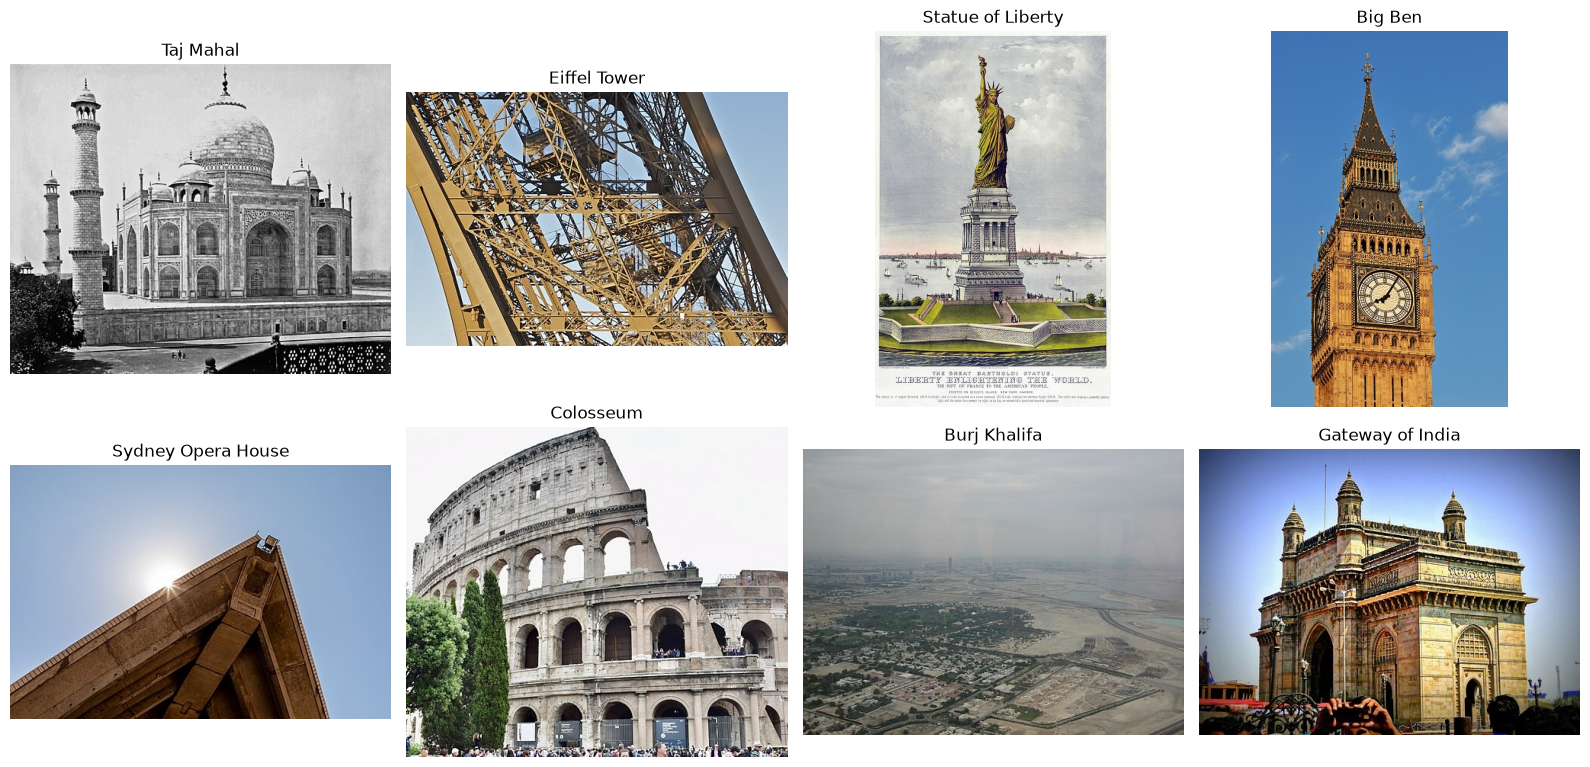

In [6]:

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, landmark in zip(axes, LANDMARKS):
    folder = os.path.join(DATASET_DIR, landmark.replace("/", "-"))
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if files:
        img = Image.open(os.path.join(folder, random.choice(files)))
        ax.imshow(img)
        ax.set_title(landmark)
    else:
        ax.set_title(landmark + "\n(no images)")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
print("Class names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


Found 400 files belonging to 8 classes.
Using 320 files for training.
Found 400 files belonging to 8 classes.
Using 80 files for validation.
Class names: ['Big Ben', 'Burj Khalifa', 'Colosseum', 'Eiffel Tower', 'Gateway of India', 'Statue of Liberty', 'Sydney Opera House', 'Taj Mahal']


In [9]:

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")


In [10]:

base_model = MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 8)                   │          10,248 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/8


C:\Users\dsouz\.conda\envs\tensorflow_project\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 27s 986ms/step - accuracy: 0.2062 - loss: 2.1785 - val_accuracy: 0.4625 - val_loss: 1.6438
Epoch 2/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 848ms/step - accuracy: 0.5406 - loss: 1.4040 - val_accuracy: 0.6375 - val_loss: 1.2549
Epoch 3/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 855ms/step - accuracy: 0.7063 - loss: 0.9322 - val_accuracy: 0.6625 - val_loss: 1.1112
Epoch 4/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 968ms/step - accuracy: 0.7500 - loss: 0.8213 - val_accuracy: 0.6875 - val_loss: 0.9867
Epoch 5/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 845ms/step - accuracy: 0.8125 - loss: 0.6137 - val_accuracy: 0.7625 - val_loss: 0.9350
Epoch 6/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 811ms/step - accuracy: 0.8750 - loss: 0.5197 - val_accuracy: 0.6875 - val_loss: 0.9011
Epoch 7/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 819ms/step - accuracy: 0.8469 - loss: 0.5034 - val_accuracy: 0.7250 - val_loss: 0.8963
Epoch 8/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 22s 872ms/step - accuracy: 0.8844 - loss: 0.4000 - val_accuracy: 0.8000 - val

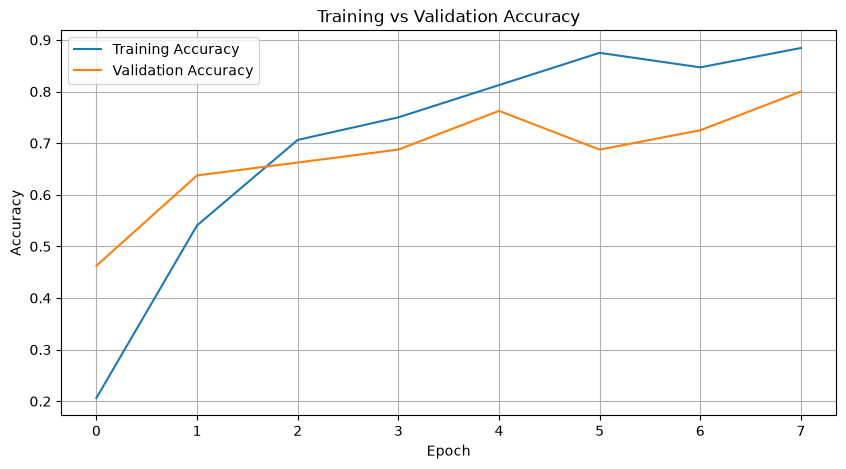

In [12]:

plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


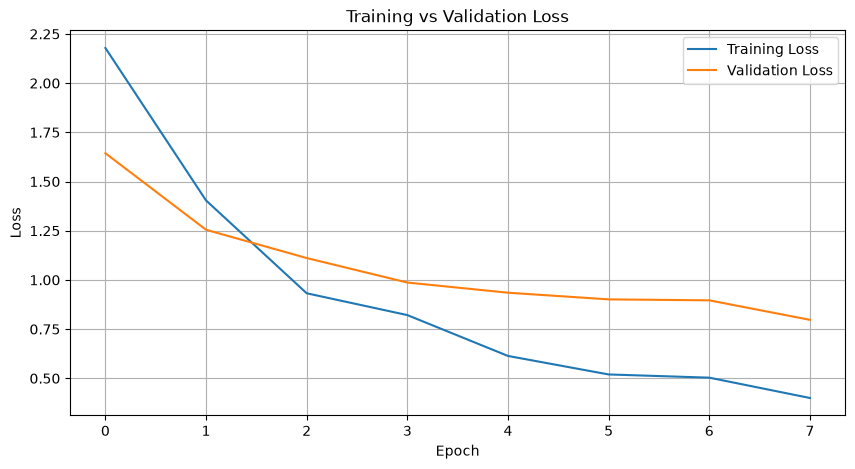

In [13]:

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [14]:

loss, accuracy = model.evaluate(val_ds, verbose=0)
print(f"Validation Loss     : {loss:.4f}")
print(f"Validation Accuracy : {accuracy * 100:.2f}%")


Validation Loss     : 0.7971
Validation Accuracy : 80.00%


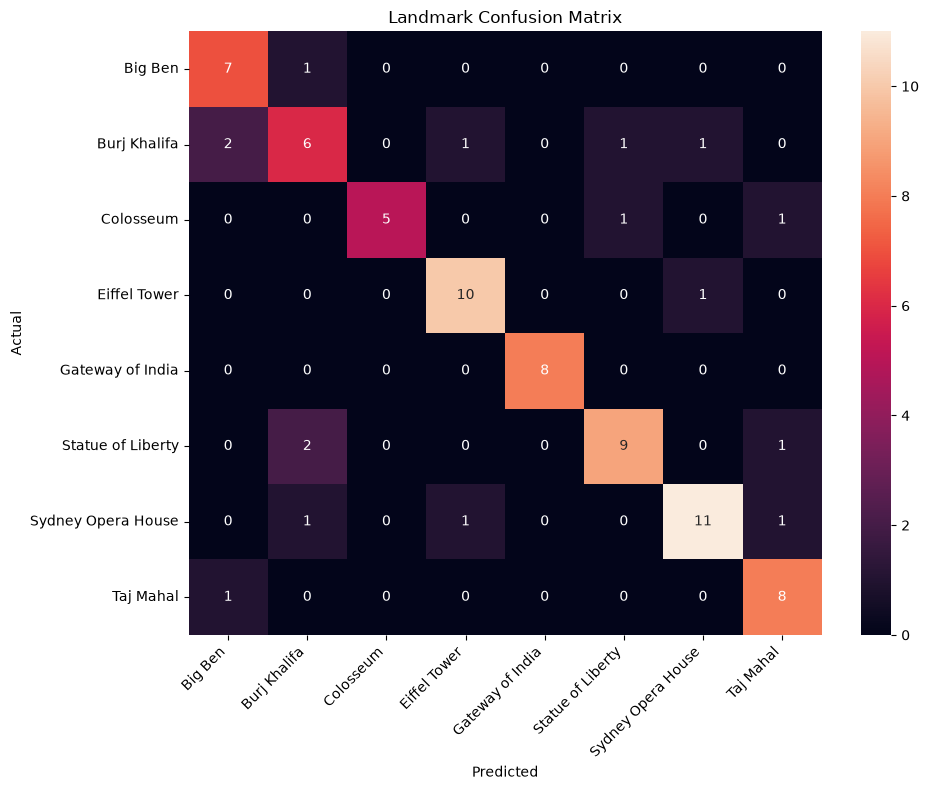

                    precision    recall  f1-score   support

           Big Ben       0.70      0.88      0.78         8
      Burj Khalifa       0.60      0.55      0.57        11
         Colosseum       1.00      0.71      0.83         7
      Eiffel Tower       0.83      0.91      0.87        11
  Gateway of India       1.00      1.00      1.00         8
 Statue of Liberty       0.82      0.75      0.78        12
Sydney Opera House       0.85      0.79      0.81        14
         Taj Mahal       0.73      0.89      0.80         9

          accuracy                           0.80        80
         macro avg       0.82      0.81      0.81        80
      weighted avg       0.81      0.80      0.80        80



In [15]:

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Landmark Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))


In [17]:

def predict_landmark(image_path, model=model):
    img = Image.open(image_path).convert("RGB")
    display(img.resize((400, 400)))

    img_array = np.array(img)
    img_resized = tf.image.resize(img_array, IMG_SIZE)
    img_batch = tf.expand_dims(img_resized, axis=0)

    probabilities = model.predict(img_batch, verbose=0)[0]

    index = int(np.argmax(probabilities))
    name = class_names[index]
    confidence = float(probabilities[index])

    print(f"\n🏛️ Predicted Landmark: {name}")
    print(f"🎯 Confidence: {confidence * 100:.2f}%")

    print("\nAll predictions:")
    for i in np.argsort(probabilities)[::-1]:
        print(f"{class_names[i]:25s}: {probabilities[i] * 100:.2f}%")

    return name, confidence


TEST_IMAGE = "test_landmark.jpg"




Testing: landmark_dataset\Burj Khalifa\022.jpg


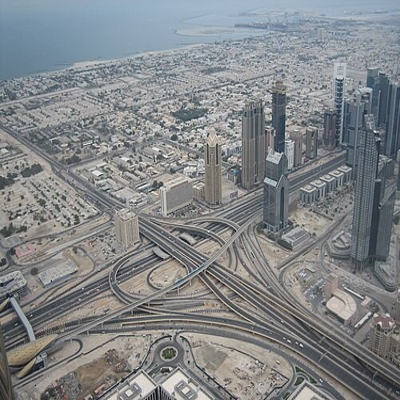


🏛️ Predicted Landmark: Burj Khalifa
🎯 Confidence: 56.19%

All predictions:
Burj Khalifa             : 56.19%
Taj Mahal                : 37.58%
Colosseum                : 1.95%
Gateway of India         : 1.79%
Eiffel Tower             : 1.35%
Big Ben                  : 0.75%
Statue of Liberty        : 0.29%
Sydney Opera House       : 0.09%


In [18]:

available = []

for landmark in LANDMARKS:
    folder = os.path.join(DATASET_DIR, landmark.replace("/", "-"))
    if os.path.exists(folder):
        for filename in os.listdir(folder):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                available.append(os.path.join(folder, filename))

if available:
    test_path = random.choice(available)
    print("Testing:", test_path)
    predict_landmark(test_path)
else:
    print("No images found. Run the download cell first.")


In [19]:

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

loss, accuracy = model.evaluate(val_ds, verbose=0)
print(f"Fine-tuned validation accuracy: {accuracy * 100:.2f}%")


Epoch 1/5


C:\Users\dsouz\.conda\envs\tensorflow_project\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.6906 - loss: 0.8782 - val_accuracy: 0.8000 - val_loss: 0.7817
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.7437 - loss: 0.8180 - val_accuracy: 0.7875 - val_loss: 0.7682
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.7969 - loss: 0.7346 - val_accuracy: 0.7875 - val_loss: 0.7578
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7844 - loss: 0.6660 - val_accuracy: 0.7875 - val_loss: 0.7514
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8188 - loss: 0.5881 - val_accuracy: 0.7875 - val_loss: 0.7439
Fine-tuned validation accuracy: 78.75%


In [20]:

model.save(MODEL_PATH)
print("Model saved:", os.path.abspath(MODEL_PATH))


Model saved: C:\Users\dsouz\landmark_detector.keras


In [21]:

print("Model is ready.")


Model is ready.
